# Bregman proximal point minimization
In a real finite-dimensional Euclidean space, let $f$ be closed, proper and convex, differentiable relative to the closed, proper, convex differentiable kernel $h$. Let $x_\star$ minimize $f$, $\alpha>0$, $R\geq0$, and $N\geq1$. All stated evaluations and proximal updates are well-defined.
$$D_{h}(u,v)=h(u)-h(v)-\langle\nabla h(v),u-v\rangle,\qquad D_{h}(x_\star,x_{0})\leq R.$$
For $k=0,\ldots,N-1$,
$$x_{k+1}\in\mathop{\rm argmin}_{x}\{\alpha f(x)+D_{h}(x,x_{k})\},\qquad \nabla h(x_{k+1})=\nabla h(x_{k})-\alpha\nabla f(x_{k+1}).$$
The performance metric is $f(x_{N})-f(x_\star)$. The supplied conjecture is $R/(\alpha N)$; the theorem below proves this bound.

## Proof Statement

### Theorem
Let $f,h$ satisfy the stated closedness, properness, convexity and differentiability assumptions, and let $x_{\star}$ minimize $f$. For $\alpha>0$, $R\geq0$ and integer $N\geq1$, suppose $D_{h}(x_{\star},x_{0})\leq R$ and all exact updates
$$x_{k+1}\in\operatorname*{argmin}_{x}\{\alpha f(x)+D_{h}(x,x_{k})\},\qquad k=0,\ldots,N-1,$$
are well-defined. The sequence
$$V_{0}=0,\qquad V_{k}=\frac{k}{N}(f(x_{k})-f(x_{\star}))+\frac{D_{h}(x_{\star},x_{k})-D_{h}(x_{\star},x_{0})}{\alpha N},\quad 1\leq k\leq N,$$
is nonincreasing. In particular,
$$f(x_{N})-f(x_{\star})\leq\frac{R}{\alpha N}.$$
The terminal index uses the same formula. No strong convexity of $h$ is assumed.

### Proof outline
Write $D_{k}=D_{h}(x_{\star},x_{k})$ and $Q^f_{u,v}=f(v)-f(u)+\langle\nabla f(v),u-v\rangle\leq0$, with $Q^h$ defined analogously. The proximal optimality relation is $\nabla h(x_{k+1})=\nabla h(x_{k})-\alpha\nabla f(x_{k+1})$.
For $V_{k}=(k/N)(f(x_{k})-f(x_{\star}))+(D_{k}-D_{0})/(\alpha N)$, direct substitution gives, for $1\leq k<N$,
$$V_{k+1}-V_{k}=\frac{Q^f_{\star,k+1}}{N}+\frac{kQ^f_{k,k+1}}{N}+\frac{(k+1)Q^h_{k+1,k}}{\alpha N}+\frac{kQ^h_{k,k+1}}{\alpha N}\leq0.$$
The first step satisfies
$$V_{1}-V_{0}=\frac{Q^f_{\star,1}}{N}+\frac{Q^h_{1,0}}{\alpha N}\leq0,\qquad V_{0}=0.$$
All multipliers are nonnegative; there are no omitted slack or square terms. Telescoping yields $V_{N}\leq0$. Finally,
$$f(x_{N})-f(x_{\star})-\frac{R}{\alpha N}=V_{N}+\frac{D_{0}-R+Q^h_{\star,N}}{\alpha N}\leq0,$$
because $D_{0}\leq R$ and $Q^h_{\star,N}=-D_{N}\leq0$. This proves the bound, including $N=1$ and $R=0$.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt

In [2]:
notebook_dir = Path(
    "C:\\Users\\Jack\\Documents\\GitHub\\PEPFlow\\examples_peppy\\_evaluations\\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\\bppm\\r03"
)
repo_root = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [str(repo_root), str(notebook_dir), str(notebook_dir / "supplementary")]

In [3]:
import pepflow as pf

In [4]:
f = pf.ConvexFunction(is_basis=True, tags=["f"])
h = pf.ConvexFunction(is_basis=True, tags=["h"])

In [5]:
def make_ctx_bppm(ctx_name, N, alpha):
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0"])
    f.set_stationary_point("x_star")
    for k in range(int(N)):
        x = f.bregman_prox(x, alpha, h, tag=f"x_{k + 1}")
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_bppm(f"ctx_{N}", N, alpha=params["alpha"])
    pb = pf.PEPBuilder(ctx)
    x0, xs = ctx["x_0"], ctx["x_star"]
    distance = h(xs) - h(x0) - h.grad(x0) * (xs - x0)
    pb.add_initial_constraint(distance.le(params["R"], name="initial_condition"))
    pb.set_performance_metric(f(ctx[f"x_{N}"]) - f(xs))
    return ctx, pb, f

## Numerical evidence
One CLARABEL sweep, with default solver options and alpha=R=1. Convex interpolation provides an upper model for the supplied differentiable class. No additional strong convexity or relative smoothness assumptions are imposed.

1 0.9999999997978739 optimal
2 0.49999999818080565 optimal
3 0.3333333297114047 optimal
4 0.249999999673264 optimal
5 0.19999999694933834 optimal
6 0.16666666623031473 optimal
7 0.14285714117216203 optimal
maximum rate discrepancy: 3.6219285903804632e-09
reciprocal increments: [1.00000001 1.00000003 0.99999997 1.00000007 0.99999994 1.00000007]


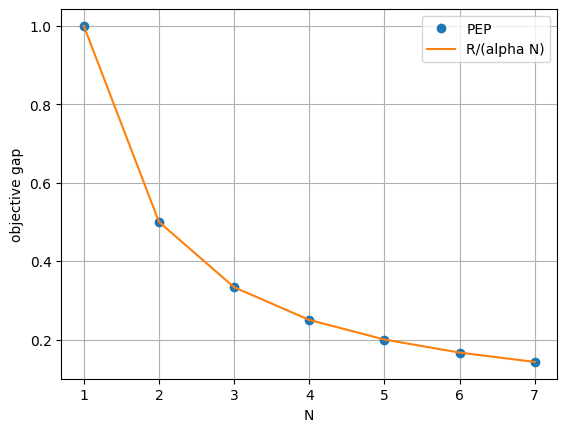

In [6]:
sweep = json.loads((notebook_dir / "supplementary/_sweep_tmp.json").read_text())
ns = np.array([row["N"] for row in sweep])
values = np.array([row["opt_value"] for row in sweep])
for row in sweep:
    print(row["N"], row["opt_value"], row["status"])
print("maximum rate discrepancy:", np.max(np.abs(values - 1 / ns)))
print("reciprocal increments:", np.diff(1 / values))
assert np.allclose(values, 1 / ns, atol=1e-5, rtol=0)
plt.plot(ns, values, "o", label="PEP")
plt.plot(ns, 1 / ns, "-", label="R/(alpha N)")
plt.xlabel("N")
plt.ylabel("objective gap")
plt.legend()
plt.grid(True)
plt.show()

The numerical evidence matches the supplied conjecture $R/(\alpha N)$. It does not constitute an all-horizon proof.

## Full PEP certificate (Block 2)
The dense and sparse primal SDP solves at $N=4$, $\alpha=R=1$ use CLARABEL defaults. Their complete dual inventories were captured from their respective single solves. We load those immutable solve results and rebuild the same context to audit every constraint contribution; no dual components are mixed.
With $Q^f_{u,v}=f(v)-f(u)+\langle\nabla f(v),u-v\rangle\leq0$ (similarly for $h$), the sparse candidate keeps optimum-to-iterate $f$ pairs, forward adjacent $f$ pairs, both orientations of adjacent $h$ pairs where their coefficients are positive, and $Q^h_{\star,N}$.
Candidate weights are $\lambda^f_{\star,i}=1/N$, $\lambda^f_{i-1,i}=(i-1)/N$ for $i\geq2$, $\lambda^h_{i,i-1}=i/(\alpha N)$, $\lambda^h_{i-1,i}=(i-1)/(\alpha N)$ for $i\geq2$, and $\lambda^h_{\star,N}=\tau=1/(\alpha N)$. The candidate is $S=0$. These are fitted candidates here; an exact all-horizon proof remains pending.

In [7]:
from pepflow.utils import Comparator

APPROVED = repo_root
b2 = json.loads((notebook_dir / "state/bppm_b2.json").read_text())
dense = json.loads((notebook_dir / "state/bppm_dense.json").read_text())
params = json.loads(b2["params_json"])
N_verify = b2["N_verify"]
ctx, pb, obj = get_pep_setup(N_verify, params)
pb.set_relaxed_constraints(b2["relaxed_constraints"])
print("dense", dense["opt_value"], "relaxed", b2["opt_value"])
print("basis", b2["basis_vectors"])
print("relaxed constraints", b2["relaxed_constraints"])
for label, saved in (("dense", dense), ("selected", b2)):
    print(label, saved["certificate_provenance"]["solver"])
    for owner in ("f", "h"):
        print(
            owner,
            {
                name: round(value, 8)
                for name, value in saved["named_dual_values"].items()
                if name.startswith(owner + ":")
                and value is not None
                and abs(value) > 1e-6
            },
        )
    print(
        "S rank at 1e-4", np.linalg.matrix_rank(np.array(saved["S_matrix"]), tol=1e-4)
    )
for label, saved in (("dense", dense), ("selected", b2)):
    for owner in ("f", "h"):
        point_labels = sorted(
            {
                tag
                for name in saved["named_dual_values"]
                if name.startswith(owner + ":")
                for tag in name.split(":")[1].split(",")
            }
        )
        dual_matrix = np.array(
            [
                [
                    saved["named_dual_values"].get(f"{owner}:{row},{col}") or 0.0
                    for col in point_labels
                ]
                for row in point_labels
            ]
        )
        print(label, owner, "multiplier display; relaxed entries displayed as zero")
        pf.pprint_labeled_matrix(dual_matrix, point_labels)

dense 0.249999999673264 relaxed 0.24999999998895409
basis ['x_0', 'x_star', 'x_1', 'grad_f(x_1)', 'grad_h(x_0)', 'x_2', 'grad_f(x_2)', 'x_3', 'grad_f(x_3)', 'x_4', 'grad_f(x_4)', 'grad_h(x_star)']
relaxed constraints ['f:x_1,x_star', 'f:x_1,x_3', 'f:x_1,x_4', 'f:x_2,x_star', 'f:x_2,x_1', 'f:x_2,x_4', 'f:x_3,x_star', 'f:x_3,x_1', 'f:x_3,x_2', 'f:x_4,x_star', 'f:x_4,x_1', 'f:x_4,x_2', 'f:x_4,x_3', 'h:x_0,x_1', 'h:x_0,x_2', 'h:x_0,x_3', 'h:x_0,x_4', 'h:x_0,x_star', 'h:x_1,x_3', 'h:x_1,x_4', 'h:x_1,x_star', 'h:x_2,x_0', 'h:x_2,x_4', 'h:x_2,x_star', 'h:x_3,x_0', 'h:x_3,x_1', 'h:x_3,x_star', 'h:x_4,x_0', 'h:x_4,x_1', 'h:x_4,x_2', 'h:x_4,x_star', 'h:x_star,x_0', 'h:x_star,x_1', 'h:x_star,x_2', 'h:x_star,x_3']
dense {'status': 'optimal', 'solver_options': {'solver': 'CLARABEL'}, 'fallback_reason': None, 'solver_name': 'CLARABEL'}
f {'f:x_star,x_1': 0.25, 'f:x_star,x_2': 0.25, 'f:x_star,x_3': 0.25, 'f:x_star,x_4': 0.25, 'f:x_1,x_2': 0.13694057, 'f:x_1,x_3': 0.07321261, 'f:x_1,x_4': 0.03984682, 

<IPython.core.display.Math object>

dense h multiplier display; relaxed entries displayed as zero


<IPython.core.display.Math object>

selected f multiplier display; relaxed entries displayed as zero


<IPython.core.display.Math object>

selected h multiplier display; relaxed entries displayed as zero


<IPython.core.display.Math object>

In [8]:
"""Fresh candidate formulas inferred from this attempt's certificate."""


def candidate_duals(N, alpha):
    values = {"initial_condition": 1 / (alpha * N), f"h:x_star,x_{N}": 1 / (alpha * N)}
    for i in range(1, N + 1):
        values[f"f:x_star,x_{i}"] = 1 / N
        values[f"h:x_{i},x_{i - 1}"] = i / (alpha * N)
        if i > 1:
            values[f"f:x_{i - 1},x_{i}"] = (i - 1) / N
            values[f"h:x_{i - 1},x_{i}"] = (i - 1) / (alpha * N)
    return values

In [9]:
candidate = candidate_duals(N_verify, params["alpha"])
for owner in ("f", "h"):
    labels = sorted(
        {
            tag
            for name in candidate
            if name.startswith(owner + ":")
            for tag in name.split(":")[1].split(",")
        }
    )
    matrix = np.array(
        [
            [candidate.get(f"{owner}:{row},{col}", 0.0) for col in labels]
            for row in labels
        ]
    )
    print("candidate multiplier matrix", owner)
    pf.pprint_labeled_matrix(matrix, labels)
lambda_error = max(
    abs(value - candidate.get(name, 0))
    for name, value in b2["named_dual_values"].items()
    if value is not None
)
print("candidate lambda max error", lambda_error)
assert lambda_error <= 1e-4

candidate multiplier matrix f


<IPython.core.display.Math object>

candidate multiplier matrix h


<IPython.core.display.Math object>

candidate lambda max error 3.34269278923216e-10


### Numerical $S$ decomposition and complete identity
The original numerical $S$ is retained, including its small entries. Its direct spectral factors satisfy $S=E^TDE$; all eigenvalues are retained. Zero is only an analytic candidate, not a replacement for this numerical certificate. We check
$$f(x_{N})-f(x_\star)-p_{N}-\sum_{c} d_{c} Q_{c}+S_{\rm numeric}=0,$$
including the initial constraint's constant, all $f$ and $h$ inequalities, and every coordinate.

In [10]:
def inventory(ctx, pb):
    rows = [(c, "initial", None, None) for c in pb.init_conditions]
    for owner in ctx.func_to_triplets:
        groups = ctx.get_constraint_data(owner)
        rows.extend(
            (c, "interpolation", str(owner), str(group))
            for group, constraints in groups.sc_dict.items()
            for c in constraints
        )
        rows.extend(
            (c, "interpolation", str(owner), str(group))
            for group, c in groups.psd_dict.items()
        )
    return rows


def max_abs(value):
    return float(np.max(np.abs(np.asarray(value, dtype=float)), initial=0.0))


def verify(ctx, pb, params, data, dense_opt):
    ctx.set_as_current()
    assert data["basis_vectors"] == [str(v) for v in ctx.basis_vectors()]
    assert data["basis_scalars"] == [str(v) for v in ctx.basis_scalars()]
    rows = inventory(ctx, pb)
    assert set(data["named_dual_values"]) == {c.name for c, *_ in rows}
    pm = pf.ExpressionManager(ctx, resolve_parameters=params)
    weighted = pf.Scalar.zero()
    duals = []
    for c, *_ in rows:
        value = data["named_dual_values"][c.name]
        if c.name in data["relaxed_constraints"]:
            assert value is None
            continue
        assert value is not None and np.isfinite(value)
        residual = c.lhs - c.rhs
        if c.cmp in (Comparator.GE, Comparator.SEQ):
            residual = -residual
        weighted += value * residual
        if c.cmp != Comparator.EQ:
            duals.append(value)
    basis = ctx.basis_vectors()
    S = np.array(data["S_matrix"])
    S_numeric = sum(
        (float(S[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(S.shape)),
        pf.Scalar.zero(),
    )
    checked = pm.eval_scalar(
        pb.performance_metric - data["opt_value"] - weighted + S_numeric
    )
    E = np.array(data["numerical_decomposition"]["ell_coords"])
    D = np.array(data["numerical_decomposition"]["D"])
    residuals = dict(
        identity_gram_max_abs=max_abs(checked.inner_prod_coords),
        identity_func_max_abs=max_abs(checked.func_coords),
        identity_offset_abs=max_abs(checked.offset),
        S_reconstruction_max_abs=max_abs(E.T @ D @ E - S),
        dense_relaxed_gap=abs(dense_opt - data["opt_value"]),
        minimum_scalar_inequality_dual=min(duals, default=0.0),
        minimum_S_eigenvalue=float(np.linalg.eigvalsh((S + S.T) / 2).min()),
        minimum_matrix_inequality_eigenvalue=0.0,
    )
    tol = json.loads((APPROVED / "settings.json").read_text())["tolerances"]
    passed = (
        data["certificate_provenance"]["solver_status"] == "optimal"
        and all(
            residuals[key] <= tol["identity_atol"]
            for key in (
                "identity_gram_max_abs",
                "identity_func_max_abs",
                "identity_offset_abs",
            )
        )
        and np.allclose(
            E.T @ D @ E,
            S,
            atol=tol["reconstruction_atol"],
            rtol=tol["reconstruction_rtol"],
        )
        and np.allclose(S, S.T, atol=tol["psd_tol"], rtol=0)
        and residuals["dense_relaxed_gap"] < tol["dense_opt_atol"]
        and min(duals, default=0.0) >= -tol["dual_tol"]
        and residuals["minimum_S_eigenvalue"] >= -tol["psd_tol"]
    )
    assert passed, residuals
    return dict(passed=bool(passed), tolerances=tol, residuals=residuals)

In [11]:
checks = verify(ctx, pb, params, b2, dense["opt_value"])
print("complete certificate checks", checks)
S_array = np.array(b2["S_matrix"])
E = np.array(b2["numerical_decomposition"]["ell_coords"])
D = np.array(b2["numerical_decomposition"]["D"])
print("spectral diagonal", np.diag(D))
pf.pprint_labeled_matrix(D, [f"ell_{i}" for i in range(len(D))], precision=12)
print("S reconstruction residual")
pf.pprint_labeled_matrix(E.T @ D @ E - S_array, b2["basis_vectors"], precision=12)
print("candidate zero S max error", np.max(np.abs(S_array)))
assert np.max(np.abs(S_array)) <= 1e-4
print("Numerical certificate verified; analytic full-PEP and Lyapunov proofs pending.")
print("True selected S matrix")
pf.pprint_labeled_matrix(S_array, b2["basis_vectors"], precision=12)

complete certificate checks {'passed': True, 'tolerances': {'identity_atol': 1e-05, 'identity_rtol': 0, 'reconstruction_atol': 0.0001, 'reconstruction_rtol': 1e-05, 'dual_tol': 1e-06, 'psd_tol': 1e-06, 'dense_opt_atol': 1e-05, 'rank_tolerance': 0.0001, 'lyapunov_component_atol': 1e-05, 'lyapunov_component_rtol': 1e-05, 'basis_zero_tol': 1e-06, 'basis_indep_tol': 1e-07, 'basis_span_tol': 1e-05}, 'residuals': {'identity_gram_max_abs': 1.925055854508916e-10, 'identity_func_max_abs': 8.89814000260003e-10, 'identity_offset_abs': 2.0593091121234863e-10, 'S_reconstruction_max_abs': 2.8836072065850606e-25, 'dense_relaxed_gap': 3.1569008518417263e-10, 'minimum_scalar_inequality_dual': 0.25000000013443113, 'minimum_S_eigenvalue': 9.285150418730221e-11, 'minimum_matrix_inequality_eigenvalue': 0.0}}
spectral diagonal [9.28515042e-11 1.60776742e-10 1.75347014e-10 1.86972248e-10
 1.92505548e-10 1.92505569e-10 1.92505571e-10 1.92505593e-10
 1.98038865e-10 2.09664092e-10 2.24234369e-10 2.92159639e-10]

<IPython.core.display.Math object>

S reconstruction residual


<IPython.core.display.Math object>

candidate zero S max error 1.925055854508916e-10
Numerical certificate verified; analytic full-PEP and Lyapunov proofs pending.
True selected S matrix


<IPython.core.display.Math object>

In [12]:
pm = pf.ExpressionManager(ctx, resolve_parameters=params)
weighted = pf.Scalar.zero()
for constraint, *_ in inventory(ctx, pb):
    multiplier = b2["named_dual_values"][constraint.name]
    if multiplier is not None:
        weighted += multiplier * (constraint.lhs - constraint.rhs)
basis = ctx.basis_vectors()
S_numeric = sum(
    (float(S_array[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(S_array.shape)),
    pf.Scalar.zero(),
)
residual = pm.eval_scalar(
    pb.performance_metric - b2["opt_value"] - weighted + S_numeric
)
pf.pprint_labeled_matrix(
    np.asarray(residual.inner_prod_coords, dtype=float),
    b2["basis_vectors"],
    precision=12,
)
print("function coordinate residual", np.asarray(residual.func_coords, dtype=float))
print("offset residual", residual.offset)
print("initial closed-form search", b2["closed_form_search"])

<IPython.core.display.Math object>

function coordinate residual [ 8.89814000e-10 -1.11022302e-16 -5.55111512e-17  2.22453500e-10
 -2.22453389e-10  1.11022302e-16 -2.22453389e-10 -2.22044605e-16
 -4.44907000e-10 -2.22453223e-10 -1.66533454e-16]
offset residual 2.0593091121234863e-10
initial closed-form search {'completed': True, 'references_reviewed': ['own input, approved generic framework; target references excluded'], 'attempts': [{'method': 'Inspect dense multipliers; drop all entries outside adjacent pairs, f optimum pairs, terminal h optimum pair', 'outcome': 'Preserves optimum; all selected multipliers match index-linear candidates', 'lambda_max_error': 3.34269278923216e-10}, {'method': 'Inspect near-zero dense and relaxed S; compare exact zero candidate to all Gram entries, and zero scalar/offset coordinates', 'outcome': 'Numerically matches zero S; exact all-horizon proof deferred', 'S_max_error': 1.925055854508916e-10}], 'unresolved_components': ['analytic all-horizon lambda/S identity and domain proof']}


## Partial-sum Lyapunov construction (Block 3)
Let $V_{0}=0$. At step $i=1,\ldots,N$, accumulate the saved multipliers on $Q^f_{\star,i}$, $Q^h_{i,i-1}$, and for $i\geq2$ on $Q^f_{i-1,i}$ and $Q^h_{i-1,i}$. Thus
$$V_{i}-V_{i-1}=d^f_{\star,i}Q^f_{\star,i}+d^h_{i,i-1}Q^h_{i,i-1}+\mathbf1_{i\geq2}\bigl(d^f_{i-1,i}Q^f_{i-1,i}+d^h_{i-1,i}Q^h_{i-1,i}\bigr)\leq0.$$
The single terminal inequality $d^h_{\star,N}Q^h_{\star,N}$ and the entire numerical PSD remainder $S$ are boundary terms. Nothing is omitted. The normalization inequality is reserved for the initial bound.
The observed Gram rank is 4 at every nonzero index for horizons 4 and 6. Fixed exclusions $(1,1)$ leave at least three indices at each horizon. The rank tolerance is $10^{-4}$ with no matrix rescaling; all singular values lie outside the ambiguity band $[10^{-5},10^{-3}]$. This is finite-sample evidence, not a theorem.

In [13]:
sys.path.insert(0, str(notebook_dir / "supplementary/helpers"))
REPO_ROOT = repo_root
certificate = json.loads((notebook_dir / "state/bppm_b3.json").read_text())
N_int = certificate["N_verify"]
params_sp = json.loads(certificate["params_json"])
ctx, pb, obj = get_pep_setup(N_int, params_sp)
pb.set_relaxed_constraints(certificate["relaxed_constraints"])

C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\bppm\r03\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



In [14]:
import hashlib
import json
import numpy as np
import pepflow as pf
import certificate as certificate_api  # ty: ignore[unresolved-import]  # Notebook bootstrap adds the helper directory to sys.path.

certificate_checked = False
certificate_keys = (
    "N_verify",
    "params_json",
    "relaxed_constraints",
    "S_matrix",
    "S_row_names",
    "S_col_names",
    "basis_vectors",
    "basis_scalars",
    "opt_value",
    "tau_sol",
    "tau_name",
    "named_dual_values",
    "constraint_metadata",
    "normalization",
    "certificate_provenance",
    "numerical_checks",
    "numerical_decomposition",
)
digest = hashlib.sha256(
    json.dumps(
        {key: certificate[key] for key in certificate_keys},
        sort_keys=True,
        separators=(",", ":"),
        allow_nan=False,
    ).encode()
).hexdigest()
assert digest == certificate["certificate_id"]
assert certificate["certificate_provenance"]["pep_type"] == "primal"
for relative, expected in certificate["certificate_provenance"][
    "source_hashes"
].items():
    source_path = (notebook_dir / relative).resolve()
    assert source_path.is_relative_to(notebook_dir)
    assert hashlib.sha256(source_path.read_bytes()).hexdigest() == expected
assert (
    __import__("pathlib").Path(pf.__file__).resolve()
    == REPO_ROOT / "pepflow/__init__.py"
)
assert N_int == certificate["N_verify"]
assert params_sp == json.loads(certificate["params_json"])
assert set(pb.relaxed_constraints) == set(certificate["relaxed_constraints"])
assert pb.ctx is ctx
basis = ctx.basis_vectors()
basis_labels = [str(v) for v in basis]
assert certificate["S_row_names"] == certificate["S_col_names"] == basis_labels
assert (
    certificate["normalization"]["tau_name"]
    == certificate["tau_name"]
    == "initial_condition"
)
assert certificate["normalization"]["initial_condition"] == "D_h(x_star,x_0)<=R"
assert certificate["normalization"]["performance_metric"] == "f(x_N)-f(x_star)"
assert certificate["normalization"]["bound_value"] == certificate["opt_value"]
assert certificate["named_dual_values"]["initial_condition"] == certificate["tau_sol"]
rows = certificate_api.inventory(ctx, pb)
assert len(rows) == len({c.name for c, *_ in rows})
assert set(certificate["constraint_metadata"]) == {c.name for c, *_ in rows}
weighted_terms = {}
extra_duals = {}
for c, origin, owner, group in rows:
    assert isinstance(c, pf.ScalarConstraint)
    expected = dict(
        origin=origin,
        owner=owner,
        group=group,
        kind="scalar",
        comparator=c.cmp.value,
        shape=[],
        relaxed=c.name in pb.relaxed_constraints,
    )
    assert expected == certificate["constraint_metadata"][c.name]
    value = certificate["named_dual_values"][c.name]
    if value is not None:
        assert c.cmp.value == "LE"
        weighted_terms[c.name] = value * (c.lhs - c.rhs)
        if origin != "interpolation" and c.name != "initial_condition":
            extra_duals[c.name] = value
checks = certificate_api.verify(
    ctx, pb, params_sp, certificate, certificate["opt_value"]
)
assert certificate["closed_form_search"]["completed"]
assert (
    abs(certificate["opt_value"] - params_sp["R"] / (params_sp["alpha"] * N_int))
    <= 1e-5
)
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
S_array = np.asarray(certificate["S_matrix"], dtype=float)
S_scalar = sum(
    (float(S_array[i, j]) * basis[i] * basis[j] for i, j in np.ndindex(S_array.shape)),
    pf.Scalar.zero(),
)
tol = certificate["numerical_checks"]["tolerances"]
certificate_checked = True

In [15]:
D = np.asarray(certificate["numerical_decomposition"]["D"], dtype=float)
E = np.asarray(certificate["numerical_decomposition"]["ell_coords"], dtype=float)
assert certificate["numerical_decomposition"]["basis_labels"] == basis_labels
assert np.allclose(E.T @ D @ E, S_array, atol=1e-4, rtol=1e-5)
# One complete PSD block retains every tiny eigencomponent as a boundary remainder.
S_piece_terms = {"S_full": S_scalar}
assert np.linalg.eigvalsh((S_array + S_array.T) / 2).min() >= -1e-6

In [16]:
grouping_checked = False
rank_tolerance = 1e-4
rank_left, rank_right = 1, 1
group_terms = {
    name: term for name, term in weighted_terms.items() if name != "initial_condition"
}
term_assignment = {}
for name in group_terms:
    owner, pair = name.split(":")
    first, second = pair.split(",")
    if name == f"h:x_star,x_{N_int}":
        term_assignment[name] = "boundary"
    elif first == "x_star" and owner == "f":
        term_assignment[name] = int(second.split("_")[1]) - 1
    else:
        i, j = int(first.split("_")[1]), int(second.split("_")[1])
        assert abs(i - j) == 1
        term_assignment[name] = max(i, j) - 1
S_assignment = {"S_full": "boundary"}
lyap = [pf.Scalar.zero()]
partial_sum = pf.Scalar.zero()
for step in range(N_int):
    partial_sum += sum(
        (
            group_terms[name]
            for name, target in term_assignment.items()
            if target == step
        ),
        pf.Scalar.zero(),
    )
    partial_sum -= sum(
        (
            S_piece_terms[name]
            for name, target in S_assignment.items()
            if target == step
        ),
        pf.Scalar.zero(),
    )
    lyap.append(partial_sum)
ranks, singular_values = [], []
for k, Vk in enumerate(lyap):
    matrix = np.asarray(pm.eval_scalar(Vk).inner_prod_coords, dtype=float)
    values = np.linalg.svd(matrix, compute_uv=False)
    singular_values.append(values.tolist())
    rank = int(np.linalg.matrix_rank(matrix, tol=rank_tolerance))
    ranks.append(rank)
    print(f"rank V_{k}: {rank}")
    if k == 0:
        print()
retained = ranks[rank_left : N_int + 1 - rank_right]
print(
    "Interior rank is constant at this N:",
    len(retained) >= 3 and len(set(retained)) == 1,
    "boundary exclusions:",
    (rank_left, rank_right),
)
boundary_names = [
    name for name, target in term_assignment.items() if target == "boundary"
]
boundary_S = [name for name, target in S_assignment.items() if target == "boundary"]
assert len(boundary_names) <= 1 and len(boundary_S) <= 1
leftover = sum((group_terms[name] for name in boundary_names), pf.Scalar.zero()) - sum(
    (S_piece_terms[name] for name in boundary_S), pf.Scalar.zero()
)
coverage = (
    lyap[N_int] + leftover - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar)
)
coverage_errors = []
for expression in (coverage, sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar):
    value = pm.eval_scalar(expression)
    errors = [
        float(np.max(np.abs(np.asarray(coords, dtype=float)), initial=0))
        for coords in (
            value.inner_prod_coords,
            value.func_coords,
            np.asarray(value.offset),
        )
    ]
    coverage_errors.append(errors)
    assert max(errors) <= 1e-5
for k in range(N_int):
    increment = sum(
        (group_terms[name] for name, target in term_assignment.items() if target == k),
        pf.Scalar.zero(),
    )
    value = pm.eval_scalar(lyap[k + 1] - lyap[k] - increment)
    assert all(
        np.allclose(np.asarray(coords, dtype=float), 0, atol=1e-5, rtol=0)
        for coords in (
            value.inner_prod_coords,
            value.func_coords,
            np.asarray(value.offset),
        )
    )
# Every increment is a sum of nonnegative numerical multipliers times convex residuals <=0.
assert all(certificate["named_dual_values"][name] >= -1e-6 for name in group_terms)
assert set(term_assignment) == set(group_terms) and set(S_assignment) == set(
    S_piece_terms
)
grouping_checked = True
rank_credible = all(
    all(value < rank_tolerance / 10 or value > rank_tolerance * 10 for value in values)
    for values in singular_values
)
print("Full-coordinate coverage errors:", coverage_errors)

rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
Interior rank is constant at this N: True boundary exclusions: (1, 1)
Full-coordinate coverage errors: [[2.7755575615628914e-17, 5.551115123125783e-17, 0.0], [0.0, 0.0, 0.0]]


In [17]:
rank_evidence = json.loads(
    (notebook_dir / "supplementary/rank_search.json").read_text()
)
for sample in rank_evidence["samples"]:
    print(
        "N",
        sample["N"],
        "retained ranks",
        sample["rank_profile"][1:-1],
        "coverage",
        sample["coverage_errors"],
    )
    assert (
        sample["certificate_checked"]
        and sample["grouping_checked"]
        and sample["rank_credible"]
    )
    assert len(sample["rank_profile"][1:-1]) >= 3
    assert set(sample["rank_profile"][1:-1]) == {4}
print(
    "Common rank 4 confirmed at N=4,6; exclusions (1,1), absolute tolerance 1e-4, no rescaling."
)

N 4 retained ranks [4, 4, 4] coverage [[2.7755575615628914e-17, 5.551115123125783e-17, 0.0], [0.0, 0.0, 0.0]]
N 6 retained ranks [4, 4, 4, 4, 4] coverage [[5.551115123125783e-17, 1.1102230246251565e-16, 0.0], [0.0, 0.0, 0.0]]
Common rank 4 confirmed at N=4,6; exclusions (1,1), absolute tolerance 1e-4, no rescaling.


## Identify the vectors composing the Lyapunov function
We use the revalidated Block 3 partial sums and search for a sparse rank-spanning basis. All indices, including the endpoints excluded from rank comparison, are reconstructed.

In [18]:
b3 = json.loads((notebook_dir / "state/bppm_b3.json").read_text())
assert certificate["certificate_id"] == b3["certificate_id"]
assert ranks == b3["rank_profile"]
print(
    "Selected rank profile",
    ranks,
    "interior 1<=k<=N-1, exceptions k=0,N; confirmed horizons",
    b3["rank_search"]["confirmed_horizons"],
)

Selected rank profile [0, 4, 4, 4, 4] interior 1<=k<=N-1, exceptions k=0,N; confirmed horizons [4, 6]


### Candidate-vector scan
Candidates include iterate-to-solution gaps, kernel gradients, cumulative objective gradients, original basis vectors, and iterate differences. Zero and duplicate coordinate vectors are removed before the column-space scan.

In [19]:
from itertools import combinations
from pepflow.lyapunov_utils import (
    vectors_in_column_space,
    find_basis_with_sparsest_coefficients,
    find_symmetric_coefficient_matrix,
)

f_obj = pf.get_func_or_oper_by_tag("f")
h_obj = pf.get_func_or_oper_by_tag("h")
assert isinstance(f_obj, pf.Function) and isinstance(h_obj, pf.Function)
x_star = ctx["x_star"]
candidate_pairs = []
for j in range(N_int + 1):
    candidate_pairs.append((f"x_{j}-x_star", ctx[f"x_{j}"] - x_star))
    candidate_pairs.append((f"grad_h(x_{j})", h_obj.grad(ctx[f"x_{j}"])))
for j in range(1, N_int + 1):
    candidate_pairs.append(
        (
            f"sum_grad_f_1_to_{j}",
            sum((f_obj.grad(ctx[f"x_{i}"]) for i in range(1, j + 1)), pf.Vector.zero()),
        )
    )
for vector in ctx.basis_vectors():
    candidate_pairs.append((str(vector), vector))
for i, j in combinations(range(N_int + 1), 2):
    candidate_pairs.append((f"x_{i}-x_{j}", ctx[f"x_{i}"] - ctx[f"x_{j}"]))
unique_pairs, candidate_coords = [], []
for label, vector in candidate_pairs:
    coords = np.asarray(pm.eval_vector(vector).coords, dtype=float)
    if np.linalg.norm(coords) < 1e-6 or any(
        np.allclose(coords, previous, atol=1e-7, rtol=0)
        for previous in candidate_coords
    ):
        continue
    unique_pairs.append((label, vector))
    candidate_coords.append(coords)
candidates = [vector for _, vector in unique_pairs]
labels_by_id = {id(vector): label for label, vector in unique_pairs}
spanning_by_k = {}
for k in range(1, N_int + 1):
    in_col = vectors_in_column_space(
        lyap[k],
        candidates,
        pep_context=ctx,
        resolve_parameters=params_sp,
        rtol=1e-4,
        atol=1e-4,
    )
    spanning_by_k[k] = in_col
    print(f"V_{k} column-space candidates:")
    for vector in in_col:
        print("   " + labels_by_id[id(vector)])

V_1 column-space candidates:
   x_0-x_star
   grad_h(x_0)
   x_1-x_star
   grad_h(x_1)
   sum_grad_f_1_to_1
   x_0-x_1
V_2 column-space candidates:
   x_0-x_star
   grad_h(x_0)
   x_2-x_star
   grad_h(x_2)
   sum_grad_f_1_to_2
   x_0-x_2
V_3 column-space candidates:
   x_0-x_star
   grad_h(x_0)
   x_3-x_star
   grad_h(x_3)
   sum_grad_f_1_to_3
   x_0-x_3
V_4 column-space candidates:
   x_0-x_star
   grad_h(x_0)
   x_4-x_star
   grad_h(x_4)
   sum_grad_f_1_to_4
   x_0-x_4


### Selected basis pattern
The following search tests the actual partial-sum matrices for every nonzero index. The adopted basis reorders the search result to put the current pair first; it keeps the same vectors and sparsity.

In [20]:
sparse_search_results = {}
for k in range(1, N_int + 1):
    sparse_basis, sparse_C = find_basis_with_sparsest_coefficients(
        lyap[k],
        spanning_by_k[k],
        pep_context=ctx,
        resolve_parameters=params_sp,
        zero_tol=1e-6,
        indep_tol=1e-7,
        span_tol=1e-5,
    )
    assert len(sparse_basis) == ranks[k]
    sparse_search_results[str(k)] = {
        "labels": [labels_by_id[id(v)] for v in sparse_basis],
        "coefficients": sparse_C.tolist(),
        "zero_count": int(np.sum(np.abs(sparse_C) < 1e-6)),
    }
    print(f"k={k}, rank {ranks[k]}")
    print("sparse basis:", sparse_search_results[str(k)]["labels"])
    print(f"zero coefficients: {np.sum(np.abs(sparse_C) < 1e-6)}/{sparse_C.size}")

k=1, rank 4
sparse basis: ['x_0-x_star', 'grad_h(x_0)', 'x_1-x_star', 'grad_h(x_1)']
zero coefficients: 12/16
k=2, rank 4
sparse basis: ['x_0-x_star', 'grad_h(x_0)', 'x_2-x_star', 'grad_h(x_2)']
zero coefficients: 12/16
k=3, rank 4
sparse basis: ['x_0-x_star', 'grad_h(x_0)', 'x_3-x_star', 'grad_h(x_3)']
zero coefficients: 12/16
k=4, rank 4
sparse basis: ['x_0-x_star', 'grad_h(x_0)', 'x_4-x_star', 'grad_h(x_4)']
zero coefficients: 12/16


For $1\leq k\leq N$, use
$$[v_{1},v_{2},v_{3},v_{4}]=[x_{k}-x_\star,\nabla h(x_{k}),x_{0}-x_\star,\nabla h(x_{0})].$$
At $k=0$, the potential is identically zero and its basis is empty. The terminal index uses the same four-vector formula as the interior.

In [21]:
def V_k_basis(k):
    assert isinstance(h_obj, pf.Function)
    if k == 0:
        return []
    return [
        ctx[f"x_{k}"] - ctx["x_star"],
        h_obj.grad(ctx[f"x_{k}"]),
        ctx["x_0"] - ctx["x_star"],
        h_obj.grad(ctx["x_0"]),
    ]


def V_k_basis_labels(k):
    return (
        []
        if k == 0
        else [f"x_{k}-x_star", f"grad_h(x_{k})", "x_0-x_star", "grad_h(x_0)"]
    )

### Coefficient matrices
In the displayed basis, the numerical fit is $C_{12}=C_{21}=1/(2\alpha N)$ and $C_{34}=C_{43}=-1/(2\alpha N)$, all other entries zero. Off-diagonal entries count twice in $\sum_{i,j} C_{ij}\langle v_{i},v_{j}\rangle$. The function part is $(k/N)(f(x_{k})-f(x_\star))+(h(x_{0})-h(x_{k}))/(\alpha N)$ and the scalar offset is zero. These remain candidate formulas until Block 5.

In [22]:
required_indices = list(range(N_int + 1))
coeff_by_k = {}
coefficient_residuals = {}
for k in required_indices:
    vectors = V_k_basis(k)
    target = np.asarray(pm.eval_scalar(lyap[k]).inner_prod_coords, dtype=float)
    if not vectors:
        assert np.linalg.matrix_rank(target, tol=1e-4) == 0
        coeff_by_k[k] = np.zeros((0, 0))
        coefficient_residuals[k] = float(np.linalg.norm(target))
        print("k=0: rank 0 basis []")
        continue
    coordinates = np.column_stack([pm.eval_vector(v).coords for v in vectors]).astype(
        float
    )
    rank = int(np.linalg.matrix_rank(coordinates, tol=1e-7))
    assert rank == len(vectors) == ranks[k]
    C = find_symmetric_coefficient_matrix(
        lyap[k],
        vectors,
        pep_context=ctx,
        resolve_parameters=params_sp,
        indep_tol=1e-7,
        span_tol=1e-5,
    )
    error = float(np.linalg.norm(coordinates @ C @ coordinates.T - target, ord="fro"))
    assert error <= 1e-5 * max(1.0, float(np.linalg.norm(target, ord="fro")))
    assert np.array_equal(C, C.T)
    coeff_by_k[k] = C
    coefficient_residuals[k] = error
    print(
        f"k={k}: rank {rank} basis {V_k_basis_labels(k)}; reconstruction residual {error}"
    )
    pf.pprint_labeled_matrix(C, V_k_basis_labels(k))


def coeff_pattern(k, N, alpha):
    if k == 0:
        return np.zeros((0, 0))
    C = np.zeros((4, 4))
    C[0, 1] = C[1, 0] = 1 / (2 * alpha * N)
    C[2, 3] = C[3, 2] = -1 / (2 * alpha * N)
    return C


fit_errors = {
    str(k): float(
        np.max(
            np.abs(coeff_by_k[k] - coeff_pattern(k, N_int, params_sp["alpha"])),
            initial=0,
        )
    )
    for k in required_indices
}
assert max(fit_errors.values()) <= 1e-4
print("Coefficient candidate residuals:", fit_errors)

for k in range(1, N_int + 1):
    print(f"Closed-form coefficient candidate k={k}")
    pf.pprint_labeled_matrix(
        coeff_pattern(k, N_int, params_sp["alpha"]), V_k_basis_labels(k)
    )

k=0: rank 0 basis []
k=1: rank 4 basis ['x_1-x_star', 'grad_h(x_1)', 'x_0-x_star', 'grad_h(x_0)']; reconstruction residual 4.614898956834533e-16


<IPython.core.display.Math object>

k=2: rank 4 basis ['x_2-x_star', 'grad_h(x_2)', 'x_0-x_star', 'grad_h(x_0)']; reconstruction residual 3.017291636902652e-10


<IPython.core.display.Math object>

k=3: rank 4 basis ['x_3-x_star', 'grad_h(x_3)', 'x_0-x_star', 'grad_h(x_0)']; reconstruction residual 3.9675930584679124e-10


<IPython.core.display.Math object>

... (6 outputs left out)

Closed-form coefficient candidate k=3


<IPython.core.display.Math object>

Closed-form coefficient candidate k=4


<IPython.core.display.Math object>

In [23]:
def V_k_structure(k):
    if k == 0:
        return pf.Scalar.zero()
    vectors = V_k_basis(k)
    C = coeff_by_k[k]
    quadratic = sum(
        (float(C[i, j]) * vectors[i] * vectors[j] for i, j in np.ndindex(C.shape)),
        pf.Scalar.zero(),
    )
    return (
        quadratic
        + (k / N_int) * (f_obj(ctx[f"x_{k}"]) - f_obj(ctx["x_star"]))
        + (h_obj(ctx["x_0"]) - h_obj(ctx[f"x_{k}"])) / (params_sp["alpha"] * N_int)
    )


component_residuals = {}
for k in range(N_int + 1):
    difference = pm.eval_scalar(V_k_structure(k) - lyap[k])
    target = pm.eval_scalar(lyap[k])
    component_residuals[str(k)] = {}
    for name, residual, target_component in (
        ("gram", difference.inner_prod_coords, target.inner_prod_coords),
        ("function", difference.func_coords, target.func_coords),
        ("offset", difference.offset, target.offset),
    ):
        error = float(np.max(np.abs(np.asarray(residual, dtype=float)), initial=0))
        scale = float(
            np.max(np.abs(np.asarray(target_component, dtype=float)), initial=0)
        )
        assert error <= 1e-5 + 1e-5 * scale, (k, name, error)
        component_residuals[str(k)][name] = error
    print(f"k={k} full component residuals:", component_residuals[str(k)])
    print(
        "function terms:",
        []
        if k == 0
        else [
            f"{k}/{N_int}*(f(x_{k})-f(x_star))",
            f"1/(alpha*{N_int})*(h(x_0)-h(x_{k}))",
        ],
        "offset: 0",
    )

k=0 full component residuals: {'gram': 0.0, 'function': 0.0, 'offset': 0.0}
function terms: [] offset: 0
k=1 full component residuals: {'gram': 1.7694179454963432e-16, 'function': 1.948850525401724e-10, 'offset': 0.0}
function terms: ['1/4*(f(x_1)-f(x_star))', '1/(alpha*4)*(h(x_0)-h(x_1))'] offset: 0
k=2 full component residuals: {'gram': 1.1122677778807599e-10, 'function': 4.6029713374196035e-10, 'offset': 0.0}
function terms: ['2/4*(f(x_2)-f(x_star))', '1/(alpha*4)*(h(x_0)-h(x_2))'] offset: 0
k=3 full component residuals: {'gram': 1.7671719643175265e-10, 'function': 7.162344051181435e-10, 'offset': 0.0}
function terms: ['3/4*(f(x_3)-f(x_star))', '1/(alpha*4)*(h(x_0)-h(x_3))'] offset: 0
k=4 full component residuals: {'gram': 1.7671719643175265e-10, 'function': 8.89814000260003e-10, 'offset': 0.0}
function terms: ['4/4*(f(x_4)-f(x_star))', '1/(alpha*4)*(h(x_0)-h(x_4))'] offset: 0


### Block 4 conclusion
The candidate full expression, reconstructed at every required numerical index, is
$$V_{k}=\frac{k}{N}(f(x_{k})-f(x_\star))+\frac{h(x_{0})-h(x_{k})+\langle\nabla h(x_{k}),x_{k}-x_\star\rangle-\langle\nabla h(x_{0}),x_{0}-x_\star\rangle}{\alpha N},\quad k\geq1,$$
with $V_{0}=0$. Equivalently the kernel part is $(D_{h}(x_\star,x_{k})-D_{h}(x_\star,x_{0}))/(\alpha N)$. Numerical reconstruction does not prove the recurrence or signs for arbitrary horizons. Block 5 must establish the exact step, initial and terminal identities.

## Closed-form conclusion
The exact candidate is
$$V_{0}=0,\qquad V_{k}=\frac{k}{N}(f(x_{k})-f(x_{\star}))+\frac{D_{h}(x_{\star},x_{k})-D_{h}(x_{\star},x_{0})}{\alpha N},\quad 1\leq k\leq N.$$
The next cells derive local multipliers from the full symbolic coordinate equations and verify the step, base and boundary identities. Their exact identities establish the formula beyond the numerical samples. The global numerical full-PEP certificate remains separately classified; no separate global analytic lambda/S claim is needed.

In [24]:
b4 = json.loads((notebook_dir / "state/bppm_b4.json").read_text())
assert b4["certificate_id"] == certificate["certificate_id"]
assert b4["numerical_reconstruction"]["certificate_id"] == certificate["certificate_id"]
print("Block 4 structure and selected certificate agree.")

Block 4 structure and selected certificate agree.


In [25]:
import sympy as sp
from typing import Any

k_symbol = sp.Symbol("k", integer=True, nonnegative=True)
N_symbol = sp.Symbol("N", integer=True, positive=True)
alpha_symbol = sp.Symbol("alpha", positive=True)
R_symbol = sp.Symbol("R", nonnegative=True)
k_parameter = pf.Parameter("k")
N_parameter = pf.Parameter("N")
alpha_parameter = pf.Parameter("alpha")
R_parameter = pf.Parameter("R")
symbolic_parameters: dict[str, Any] = {
    "k": k_symbol,
    "N": N_symbol,
    "alpha": alpha_symbol,
    "R": R_symbol,
}


def bregman(kernel, u, v):
    return kernel(u) - kernel(v) - kernel.grad(v) * (u - v)


def symbolic_components(expression, manager):
    value = manager.eval_scalar(pf.Scalar.zero() + expression, sympy_mode=True)
    gram = sp.Matrix(value.inner_prod_coords).applyfunc(sp.simplify)
    functions = sp.Matrix(list(value.func_coords)).applyfunc(sp.simplify)
    offset = sp.simplify(sp.sympify(value.offset))
    return gram, functions, offset


def exact_check(name, LHS, RHS, manager, context):
    diff = LHS - RHS
    gram, functions, offset = symbolic_components(diff, manager)
    assert all(term == 0 for term in [*gram, *functions, offset]), (
        name,
        gram,
        functions,
        offset,
    )
    print(name + " Gram residual:")
    pf.pprint_labeled_matrix(
        np.asarray(gram.tolist(), dtype=object),
        [str(v) for v in context.basis_vectors()],
    )
    print(name + " function residual:", functions)
    print(name + " offset residual:", offset)
    return {
        "gram_exact_zero": True,
        "function_exact_zero": True,
        "offset_exact_zero": True,
    }

## Symbolic Step Recursion Verification

For $1\leq k<N$, let $Q^f_{u,v}=f(v)-f(u)+\langle\nabla f(v),u-v\rangle$ and define $Q^h$ likewise. Verify
$$V_{k+1}-V_{k}=\frac{Q^f_{\star,k+1}}{N}+\frac{kQ^f_{k,k+1}}{N}+\frac{(k+1)Q^h_{k+1,k}}{\alpha N}+\frac{kQ^h_{k,k+1}}{\alpha N}.$$
The exact residual $\mathrm{LHS}-\mathrm{RHS}$ must vanish. We first solve for all four multipliers from every coordinate, using the actual relation $\nabla h(x_{k+1})=\nabla h(x_{k})-\alpha\nabla f(x_{k+1})$.

In [26]:
ctx_step = pf.PEPContext("bppm_symbolic_step").set_as_current()
f_step = pf.ConvexFunction(is_basis=True, tags=["f_{step}"])
h_step = pf.ConvexFunction(is_basis=True, tags=["h_{step}"])
xs_step = f_step.set_stationary_point("x_{star,step}")
x0_step = pf.Vector(is_basis=True, tags=["x_{0,step}"])
xk_step = pf.Vector(is_basis=True, tags=["x_{k}"])
xp_step = pf.Vector(is_basis=True, tags=["x_{k+1}"])
gp_step = f_step.grad(xp_step)
h_step.add_point_with_grad_restriction(
    xp_step, h_step.grad(xk_step) - alpha_parameter * gp_step
)
D0_step = bregman(h_step, xs_step, x0_step)
Vk_step = k_parameter / N_parameter * (f_step(xk_step) - f_step(xs_step)) + (
    bregman(h_step, xs_step, xk_step) - D0_step
) / (alpha_parameter * N_parameter)
Vp_step = (k_parameter + 1) / N_parameter * (f_step(xp_step) - f_step(xs_step)) + (
    bregman(h_step, xs_step, xp_step) - D0_step
) / (alpha_parameter * N_parameter)
Q_star = f_step.interp_ineq(xs_step, xp_step)
Q_forward = f_step.interp_ineq(xk_step, xp_step)
H_reverse = h_step.interp_ineq(xp_step, xk_step)
H_forward = h_step.interp_ineq(xk_step, xp_step)
mu_symbols = sp.symbols("mu_star mu_f mu_reverse mu_forward", real=True)
mu_parameters = [pf.Parameter(str(s)) for s in mu_symbols]
LHS_step = Vp_step - Vk_step
RHS_unknown = sum(
    (m * q for m, q in zip(mu_parameters, (Q_star, Q_forward, H_reverse, H_forward))),
    pf.Scalar.zero(),
)
unknown_parameters: dict[str, Any] = {
    **symbolic_parameters,
    **{str(s): s for s in mu_symbols},
}
pm_unknown = pf.ExpressionManager(ctx_step, resolve_parameters=unknown_parameters)
gram_eq, function_eq, offset_eq = symbolic_components(
    LHS_step - RHS_unknown, pm_unknown
)
equations = [term for term in [*gram_eq, *function_eq, offset_eq] if term != 0]
solutions = sp.solve(equations, mu_symbols, dict=True)
expected = {
    mu_symbols[0]: 1 / N_symbol,
    mu_symbols[1]: k_symbol / N_symbol,
    mu_symbols[2]: (k_symbol + 1) / (alpha_symbol * N_symbol),
    mu_symbols[3]: k_symbol / (alpha_symbol * N_symbol),
}
assert len(solutions) == 1
assert all(
    sp.simplify(solutions[0][key] - value) == 0 for key, value in expected.items()
)
print("Exact local multiplier solution:", solutions[0])
RHS_step = (
    Q_star / N_parameter
    + k_parameter / N_parameter * Q_forward
    + (k_parameter + 1) / (alpha_parameter * N_parameter) * H_reverse
    + k_parameter / (alpha_parameter * N_parameter) * H_forward
)
pm_step = pf.ExpressionManager(ctx_step, resolve_parameters=symbolic_parameters)
step_check = exact_check("Step", LHS_step, RHS_step, pm_step, ctx_step)

Exact local multiplier solution: {mu_f: k/N, mu_forward: k/(N*alpha), mu_reverse: (k + 1)/(N*alpha), mu_star: 1/N}
Step Gram residual:


<IPython.core.display.Math object>

Step function residual: Matrix([[0], [0], [0], [0], [0], [0], [0]])
Step offset residual: 0


## Base Case and Boundary Symbolic Verification

Build an independent first-step context. With $V_{0}=0$, verify
$$V_{1}-V_{0}=\frac{Q^f_{\star,1}}{N}+\frac{Q^h_{1,0}}{\alpha N}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must vanish in every coordinate. This avoids evaluating $f(x_{0})$ with a nominal zero coefficient and applies also when $N=1$.

In [27]:
ctx_base = pf.PEPContext("bppm_symbolic_base").set_as_current()
f_base = pf.ConvexFunction(is_basis=True, tags=["f_{base}"])
h_base = pf.ConvexFunction(is_basis=True, tags=["h_{base}"])
xs_base = f_base.set_stationary_point("x_{star,base}")
x0_base = pf.Vector(is_basis=True, tags=["x_{0,base}"])
x1_base = pf.Vector(is_basis=True, tags=["x_{1,base}"])
g1_base = f_base.grad(x1_base)
h_base.add_point_with_grad_restriction(
    x1_base, h_base.grad(x0_base) - alpha_parameter * g1_base
)
V0_base = pf.Scalar.zero()
V1_base = (f_base(x1_base) - f_base(xs_base)) / N_parameter + (
    bregman(h_base, xs_base, x1_base) - bregman(h_base, xs_base, x0_base)
) / (alpha_parameter * N_parameter)
LHS_base = V1_base - V0_base
RHS_base = f_base.interp_ineq(xs_base, x1_base) / N_parameter + h_base.interp_ineq(
    x1_base, x0_base
) / (alpha_parameter * N_parameter)
pm_base = pf.ExpressionManager(ctx_base, resolve_parameters=symbolic_parameters)
base_check = exact_check("Base", LHS_base, RHS_base, pm_base, ctx_base)
zero_gram, zero_functions, zero_offset = symbolic_components(V0_base, pm_base)
assert all(term == 0 for term in [*zero_gram, *zero_functions, zero_offset])

Base Gram residual:


<IPython.core.display.Math object>

Base function residual: Matrix([[0], [0], [0], [0], [0]])
Base offset residual: 0


### Boundary Identity Symbolic Verification

In a separate symbolic terminal context, verify
$$f(x_{N})-f(x_{\star})-\frac{R}{\alpha N}=V_{N}+\frac{D_{h}(x_{\star},x_{0})-R+Q^h_{\star,N}}{\alpha N}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must vanish, including the radius constant. Convexity gives $Q^h_{\star,N}=-D_{h}(x_{\star},x_{N})\leq0$.

In [28]:
ctx_terminal = pf.PEPContext("bppm_symbolic_terminal").set_as_current()
f_terminal = pf.ConvexFunction(is_basis=True, tags=["f_{terminal}"])
h_terminal = pf.ConvexFunction(is_basis=True, tags=["h_{terminal}"])
xs_terminal = f_terminal.set_stationary_point("x_{star,terminal}")
x0_terminal = pf.Vector(is_basis=True, tags=["x_{0,terminal}"])
xN_terminal = pf.Vector(is_basis=True, tags=["x_{N,terminal}"])
D0_terminal = bregman(h_terminal, xs_terminal, x0_terminal)
DN_terminal = bregman(h_terminal, xs_terminal, xN_terminal)
gap_terminal = f_terminal(xN_terminal) - f_terminal(xs_terminal)
VN_terminal = gap_terminal + (DN_terminal - D0_terminal) / (
    alpha_parameter * N_parameter
)
initial_residual = D0_terminal - R_parameter
terminal_residual = h_terminal.interp_ineq(xs_terminal, xN_terminal)
LHS_boundary = gap_terminal - R_parameter / (alpha_parameter * N_parameter)
RHS_boundary = VN_terminal + (initial_residual + terminal_residual) / (
    alpha_parameter * N_parameter
)
pm_terminal = pf.ExpressionManager(ctx_terminal, resolve_parameters=symbolic_parameters)
boundary_check = exact_check(
    "Boundary", LHS_boundary, RHS_boundary, pm_terminal, ctx_terminal
)
for multiplier in expected.values():
    assert sp.simplify(multiplier).is_nonnegative is True
assert (1 / (alpha_symbol * N_symbol)).is_positive is True
print(
    "Signs: all local multipliers nonnegative for integer k>=0, N>=1, alpha>0; initial and terminal multipliers positive."
)
print(
    "Domain: interior steps 1<=k<N, separate base k=0; N=1 uses base and terminal only. R>=0; no division by R."
)
print(
    "Normalization: V0=0, VN<=0, initial_residual<=0, terminal_residual=-D_h(x_star,x_N)<=0 imply gap<=R/(alpha*N)."
)

Boundary Gram residual:

<IPython.core.display.Math object>

Boundary function residual: Matrix([[0], [0], [0], [0], [0]])
Boundary offset residual: 0
Signs: all local multipliers nonnegative for integer k>=0, N>=1, alpha>0; initial and terminal multipliers positive.
Domain: interior steps 1<=k<N, separate base k=0; N=1 uses base and terminal only. R>=0; no division by R.
Normalization: V0=0, VN<=0, initial_residual<=0, terminal_residual=-D_h(x_star,x_N)<=0 imply gap<=R/(alpha*N).


### Signs, domain and telescoping
Each $Q^f,Q^h$ is nonpositive by convexity. For integer $N\geq1$, $\alpha>0$ and $k\geq0$, the four local multipliers $1/N$, $k/N$, $(k+1)/(\alpha N)$ and $k/(\alpha N)$ are nonnegative. Thus the separate base gives $V_{1}\leq0$, and the step identity gives $V_{k+1}\leq V_{k}$ for $1\leq k<N$. Hence $V_{N}\leq V_{0}=0$.
The initial bound $D_{h}(x_{\star},x_{0})-R\leq0$, terminal convexity residual, and positive denominator $\alpha N$ make the boundary identity's right side nonpositive. Therefore
$$f(x_{N})-f(x_{\star})\leq\frac{R}{\alpha N}.$$
For $N=1$, only the separately verified base and boundary are required. $R=0$ is permitted because no step divides by $R$. The equivalent nonnegative energy is $W_{k}=\alpha k(f(x_{k})-f(x_{\star}))+D_{h}(x_{\star},x_{k})$ for $k\geq1$, with $W_{0}=D_{h}(x_{\star},x_{0})$; it satisfies $W_{k}=\alpha N V_{k}+W_{0}$.
The numerical full-PEP certificate and the exact local Lyapunov proof are verified separately. The latter is complete; a separate global analytic full-PEP formula is not claimed.